## 01 - Data Exploration: Instacart Grocery Orders
Goal: understand the data before building  a "Buy it again" model that predicts which previously bought products a user will reorder in their next order.

In [71]:
import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt 
import seaborn as sns

print("All libraries imported successfully")
print("Pandas version: ", pd.__version__)
print("NumPy version: ", np.__version__)

All libraries imported successfully
Pandas version:  3.0.6
NumPy version:  2.5.4


### 1. Setup
Libraries, file path and the DuckDB connection

In [98]:
from pathlib import Path

orders_path = RAW_DATA_DIR/"orders.csv"
prior_path = RAW_DATA_DIR/"order_products__prior.csv"
train_path = RAW_DATA_DIR/"order_products__train.csv"
products_path = RAW_DATA_DIR/"products.csv"
departments_path = RAW_DATA_DIR/"departments.csv"

PROJECT_DIR = Path.cwd().parent
RAW_DATA_DIR = PROJECT_DIR/"data"/"raw"

print("Project directory:", PROJECT_DIR)
print("\nFiles found: ")

for file in sorted(RAW_DATA_DIR.glob("*")):
    if file.is_file():
        print(f"{file.name} - {file.stat().st_size/(1024**2):.2f} MB")

Project directory: c:\grocery_reorder_prediction

Files found: 
aisles.csv - 0.00 MB
departments.csv - 0.00 MB
order_products__prior.csv - 550.80 MB
order_products__train.csv - 23.54 MB
orders.csv - 103.92 MB
products.csv - 2.07 MB


In [73]:
con = duckdb.connect()

## 2. Orders table
One row per order: who placed it, when and which set it belongs to (prior/ train/ test). 

In [74]:
orders_schema = con.execute(
    "DESCRIBE SELECT * FROM read_csv_auto(?)",
    [str(orders_path)]
).df()

display(orders_schema)

,column_name,column_type,null,key,default,extra
0,order_id,BIGINT,YES,None,None,None
1,user_id,BIGINT,YES,None,None,None
2,eval_set,VARCHAR,YES,None,None,None
3,order_number,BIGINT,YES,None,None,None
4,order_dow,BIGINT,YES,None,None,None
5,order_hour_of_day,VARCHAR,YES,None,None,None
6,days_since_prior_order,DOUBLE,YES,None,None,None


#### order_hour_of_day is in VARCHAR, it sorts as text so one can't perform maths on it

In [75]:
con.execute(f"""
    CREATE OR REPLACE TABLE orders AS
    SELECT
        order_id,
        user_id,
        eval_set,
        order_number,
        order_dow,
        CAST(order_hour_of_day AS INTEGER) AS order_hour_of_day,
        days_since_prior_order
    FROM read_csv_auto('{orders_path.as_posix()}')
""")

display(con.execute("DESCRIBE orders").df())

,column_name,column_type,null,key,default,extra
0,order_id,BIGINT,YES,None,None,None
1,user_id,BIGINT,YES,None,None,None
2,eval_set,VARCHAR,YES,None,None,None
3,order_number,BIGINT,YES,None,None,None
4,order_dow,BIGINT,YES,None,None,None
5,order_hour_of_day,INTEGER,YES,None,None,None
6,days_since_prior_order,DOUBLE,YES,None,None,None


In [76]:
orders_count = con.execute(
    "SELECT COUNT(*) AS total_orders FROM orders").df()

display(orders_count)

,total_orders
0,3421083


In [77]:
orders_summary = con.execute("""
    SELECT 
        eval_set,
        COUNT(*) AS order_count,
        COUNT(DISTINCT user_id) AS unique_users,
        COUNT(DISTINCT order_id) AS unique_orders
    FROM orders
    GROUP BY eval_set
    ORDER BY eval_set
""").df()

display(orders_summary)

,eval_set,order_count,unique_users,unique_orders
0,prior,3214874,206209,3214874
1,test,75000,75000,75000
2,train,131209,131209,131209


### 3. Order products (prior orders)
One row per product in each past order. This is the purchase history the model learns from.

In [78]:
prior_schema = con.execute(
    "DESCRIBE SELECT * FROM read_csv_auto(?)",
    [str(prior_path)]
).df()

display(prior_schema)

,column_name,column_type,null,key,default,extra
0,order_id,BIGINT,YES,None,None,None
1,product_id,BIGINT,YES,None,None,None
2,add_to_cart_order,BIGINT,YES,None,None,None
3,reordered,BIGINT,YES,None,None,None


In [79]:
prior_stats = con.execute("""
    SELECT
        COUNT(*) AS total_product_rows,
        COUNT(DISTINCT order_id) AS unique_orders,
        COUNT(DISTINCT product_id) AS unique_products,
        CAST(SUM(reordered) AS BIGINT) AS reorder_rows,
        ROUND (AVG(reordered), 4) AS reorder_rate
    FROM read_csv_auto(?)    
""", [str(prior_path)]).df()

display(prior_stats)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_product_rows,unique_orders,unique_products,reorder_rows,reorder_rate
0,32434489,3214874,49677,19126536,0.5897


Observation: 49,677 products appear in prior orders, but products.csv lists 49,688. So 11 products were never bought in any prior order. They can never appear in anyone’s purchase history, so a “Buy it again” model can never recommend them. That’s only about 0.02% of the catalogue, so it doesn’t affect the project.

### 4. Product
Product names, aisles and departments plus the most purchased overall

In [80]:
products_schema = con.execute(
    "DESCRIBE SELECT * FROM read_csv_auto(?)",
    [str(products_path)]
).df()

display(products_schema)

,column_name,column_type,null,key,default,extra
0,product_id,BIGINT,YES,None,None,None
1,product_name,VARCHAR,YES,None,None,None
2,aisle_id,BIGINT,YES,None,None,None
3,department_id,BIGINT,YES,None,None,None


In [81]:
products_preview = con.execute("""
    SELECT *
    FROM read_csv_auto(?)
    LIMIT 10
""", [str(products_path)]).df()

display(products_preview)

,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13
5,6,Dry Nose Oil,11,11
6,7,Pure Coconut Water With Orange,98,7
7,8,Cut Russet Potatoes Steam N' Mash,116,1
8,9,Light Strawberry Blueberry Yogurt,120,16
9,10,Sparkling Orange Juice & Prickly Pear Beverage,115,7


In [82]:
top_products = con.execute("""
    SELECT 
        p.product_id,
        p.product_name,
        COUNT(*) AS total_purchases,
        CAST(SUM(op.reordered) AS BIGINT) AS reorder_count,
        ROUND(AVG(op.reordered)*100,2) AS reorder_percentage
    FROM read_csv_auto(?) AS op
    JOIN read_csv_auto(?) AS p
        ON op.product_id = p.product_id
    GROUP BY 
        p.product_id,
        p.product_name
    ORDER BY total_purchases DESC
    LIMIT 10
""", [str(prior_path), str(products_path)]).df()

display(top_products)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,product_id,product_name,total_purchases,reorder_count,reorder_percentage
0,24852,Banana,472565,398609,84.35
1,13176,Bag of Organic Bananas,379450,315913,83.26
2,21137,Organic Strawberries,264683,205845,77.77
3,21903,Organic Baby Spinach,241921,186884,77.25
4,47209,Organic Hass Avocado,213584,170131,79.66
5,47766,Organic Avocado,176815,134044,75.81
6,47626,Large Lemon,152657,106255,69.60
7,16797,Strawberries,142951,99802,69.82
8,26209,Limes,140627,95768,68.10
9,27845,Organic Whole Milk,137905,114510,83.04


Observation: The most purchased products are almost all fresh produce (bananas, strawberries, spinach, avocados), and they are also reordered very often (70–85%). Risk for the model: a simple model could recommend the same popular produce to everyone, so the row would look the same for every user and show items people would buy anyway. The model needs user-specific signals (what this user buys and when), and the row may need a diversity rule so it isn’t filled with one department.

### 5. One user's history (user 1)
Looking at a single user to understand what "prior" and "train" orders mean in practice.

In [83]:
user_history = con.execute("""
    SELECT 
        user_id,
        order_id,
        order_number,
        eval_set,
        order_dow,
        order_hour_of_day,
        days_since_prior_order
    FROM orders
    WHERE user_id = 1
    ORDER BY order_number
""").df()

display(user_history)

,user_id,order_id,order_number,eval_set,order_dow,order_hour_of_day,days_since_prior_order
0,1,2539329,1,prior,2,8,NaN
1,1,2398795,2,prior,3,7,15.0
2,1,473747,3,prior,3,12,21.0
3,1,2254736,4,prior,4,7,29.0
4,1,431534,5,prior,4,15,28.0
5,1,3367565,6,prior,2,7,19.0
6,1,550135,7,prior,1,9,20.0
7,1,3108588,8,prior,1,14,14.0
8,1,2295261,9,prior,1,16,0.0
9,1,2550362,10,prior,4,8,30.0


In [85]:
user_products = con.execute("""
    SELECT
        p.product_name,
        COUNT(*) AS times_purchased,
        MAX(o.order_number) AS last_order_number,
        CAST(SUM(op.reordered) AS BIGINT) AS previous_reorders
    FROM read_csv_auto(?) AS op
    JOIN orders AS o
        ON op.order_id = o.order_id
    JOIN read_csv_auto(?) AS p
        ON op.product_id = p.product_id
    WHERE o.user_id = 1
        AND o.eval_set = 'prior'
    GROUP BY p.product_id, p.product_name
    ORDER BY times_purchased DESC
    LIMIT 10
""", [
    str(prior_path),
    str(products_path)
]).df()

display(user_products)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,product_name,times_purchased,last_order_number,previous_reorders
0,Soda,10,10,9
1,Original Beef Jerky,10,10,9
2,Pistachios,9,10,8
3,Organic String Cheese,8,10,7
4,Cinnamon Toast Crunch,3,10,2
5,Zero Calorie Cola,3,10,2
6,Aged White Cheddar Popcorn,2,2,1
7,XL Pick-A-Size Paper Towel Rolls,2,4,1
8,Organic Half & Half,2,9,1
9,Bag of Organic Bananas,2,5,1


### 5.1 What user 1 actually bought next
The 'train' order is the "next basket" we want to predict

In [86]:
actual_next_order = con.execute("""
    SELECT
        p.product_name,
        op.add_to_cart_order,
        op.reordered
    FROM read_csv_auto(?) AS op
    JOIN orders AS o
        ON op.order_id = o.order_id
    JOIN read_csv_auto(?) AS p
        ON op.product_id = p.product_id
    WHERE o.user_id = 1
      AND o.eval_set = 'train'
    ORDER BY op.add_to_cart_order
""", [
    str(train_path),
    str(products_path)
]).df()

display(actual_next_order)

,product_name,add_to_cart_order,reordered
0,Soda,1,1
1,Organic String Cheese,2,1
2,0% Greek Strained Yogurt,3,1
3,XL Pick-A-Size Paper Towel Rolls,4,1
4,Milk Chocolate Almonds,5,1
5,Pistachios,6,1
6,Cinnamon Toast Crunch,7,1
7,Aged White Cheddar Popcorn,8,1
8,Organic Whole Milk,9,0
9,Organic Half & Half,10,1


### 6. A frequency baseline for user 1
Recommend the 10 products user 1 bought most often, then check them again the real next basket.

In [87]:
k=10
user_baseline = con.execute(f"""
    SELECT 
        p.product_id,
        p.product_name,
        COUNT(*) AS purchase_count,
        MAX(o.order_number) AS last_order_number
    FROM read_csv_auto(?) AS op
    JOIN orders o
        ON op.order_id = o.order_id 
    JOIN read_csv_auto(?) AS p
        ON op.product_id = p.product_id
    WHERE o.user_id = 1
      AND o.eval_set = 'prior'
    GROUP BY p.product_id, p.product_name
    ORDER BY purchase_count DESC, last_order_number DESC
    LIMIT {k}
""",[
    str(prior_path),
    str(products_path)
]).df()

display(user_baseline)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,product_id,product_name,purchase_count,last_order_number
0,12427,Original Beef Jerky,10,10
1,196,Soda,10,10
2,10258,Pistachios,9,10
3,25133,Organic String Cheese,8,10
4,13032,Cinnamon Toast Crunch,3,10
5,46149,Zero Calorie Cola,3,10
6,49235,Organic Half & Half,2,9
7,13176,Bag of Organic Bananas,2,5
8,26405,XL Pick-A-Size Paper Towel Rolls,2,4
9,26088,Aged White Cheddar Popcorn,2,2


In [88]:
recommended_ids = set(user_baseline["product_id"])
actual_ids = set(
    con.execute(f"""
        SELECT op.product_id
        FROM read_csv_auto(?) AS op
        JOIN orders AS o
            ON op.order_id = o.order_id
        WHERE o.user_id = 1
          AND o.eval_set = 'train'    
""",[str(train_path)]).df()["product_id"]
)

correct_recommendations = recommended_ids & actual_ids

precision_at_k = len(correct_recommendations)/len(recommended_ids)
recall_at_k = len(correct_recommendations)/len(actual_ids)

print("Recommended products: ", len(recommended_ids))
print("Actual products: ", len(actual_ids))
print("Correct Recommendations: ", len(correct_recommendations))
print(f"Precision@{k}: {precision_at_k:.3f}")
print(f"Recall@{k}: {recall_at_k:.3f}")

print("\nCorrectly recommended products: ")
print(
    user_baseline[
        user_baseline["product_id"].isin(correct_recommendations)
    ]["product_name"].tolist()
)

Recommended products:  10
Actual products:  11
Correct Recommendations:  8
Precision@10: 0.800
Recall@10: 0.727

Correctly recommended products: 
['Soda', 'Pistachios', 'Organic String Cheese', 'Cinnamon Toast Crunch', 'Zero Calorie Cola', 'Organic Half & Half', 'XL Pick-A-Size Paper Towel Rolls', 'Aged White Cheddar Popcorn']


precision divides the correct items by the number of products shown(k=10).Recall divides them by the number of products actually in the basket (11). They were equal before only because k happened to equal the basket size (11). With a fixed k they differ: 8/10 = 0.80 and 8/11 = 0.73

Frequency alone misses items brought recently but rarely. Milk Chocolate Almonds was bought only once, but in the last order and it was bought again. Frequency also misses items with a weak personal history, like 0% Greek Yogurt. Features for recency, timing since last purchase and how often a product is reordered by all users could help

Organic Whole Milk had never been bought by this user before. No "buy it again" model can predict new items, so a model's best possible recall is limited by how much of the basket consists of repeat items.

This in one user only. The real evaluation must average these metrics across all users

### 7.1 Orders per user

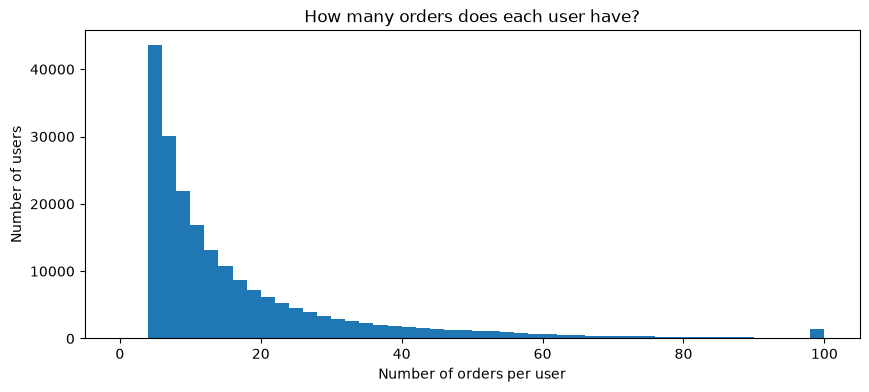

count    206209.000000
mean         16.590367
std          16.654774
min           4.000000
25%           6.000000
50%          10.000000
75%          20.000000
max         100.000000
Name: n_orders, dtype: float64

In [110]:
orders_per_user = con.execute("""
    SELECT user_id, COUNT(*) AS n_orders 
    FROM orders
    GROUP BY user_id    
""").df()

plt.figure(figsize=(10,4))
plt.hist(orders_per_user["n_orders"], bins=range(0,102,2))
plt.xlabel("Number of orders per user")
plt.ylabel("Number of users")
plt.title("How many orders does each user have?")
plt.show()

orders_per_user["n_orders"].describe()

### 7.2 Days between orders

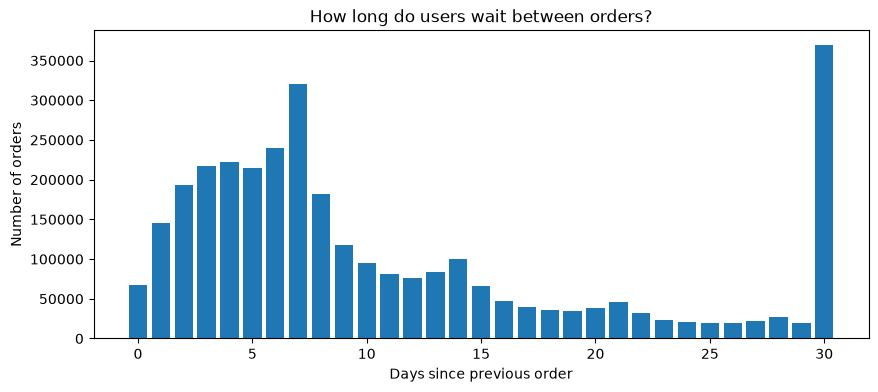

In [91]:
gaps = con.execute("""
    SELECT days_since_prior_order AS days, COUNT(*) AS n_orders
    FROM orders
    WHERE days_since_prior_order IS NOT NULL
    GROUP BY days
    ORDER BY days
""").df()

plt.figure(figsize=(10,4))
plt.bar(gaps["days"], gaps["n_orders"])
plt.xlabel("Days since previous order")
plt.ylabel("Number of orders")
plt.title("How long do users wait between orders?")
plt.show()

### 7.3 Basket Size(Items per order)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

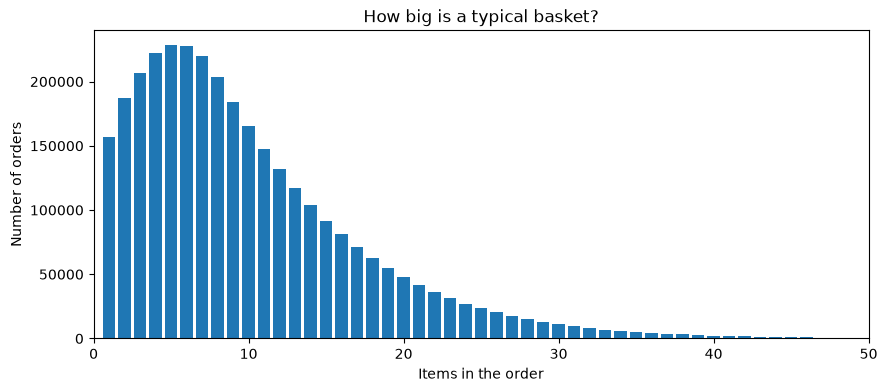

In [97]:
b_size = con.execute("""
    SELECT basket_size, COUNT(*) AS n_orders
    FROM (
        SELECT order_id, COUNT(*) AS basket_size
        FROM read_csv_auto(?)
        GROUP BY order_id
    ) AS baskets
    GROUP BY basket_size
    ORDER BY basket_size
""", [str(prior_path)]).df()

plt.figure(figsize=(10,4))
plt.bar(b_size["basket_size"], b_size["n_orders"])
plt.xlim(0,50)
plt.xlabel("Items in the order")
plt.ylabel("Number of orders")
plt.title("How big is a typical basket?")
plt.show()

### 7.4 Reorder rate by department

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

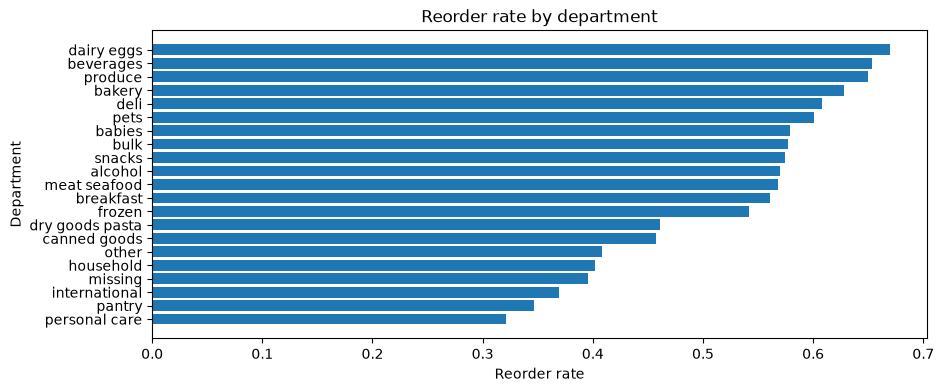

In [111]:
re_rate = con.execute("""
    SELECT d.department, 
    COUNT(*) AS items_bought,
    ROUND(AVG(op.reordered), 3) AS reorder_rate
    FROM read_csv_auto(?) AS op
    JOIN read_csv_auto(?) AS p ON op.product_id = p.product_id
    JOIN read_csv_auto(?) AS d ON p.department_id = d.department_id
    GROUP BY d.department
    ORDER BY reorder_rate DESC
""", [str(prior_path), str(products_path), str(departments_path)]).df()

plt.figure(figsize=(10,4))
plt.barh(re_rate["department"], re_rate["reorder_rate"])
plt.gca().invert_yaxis()
plt.xlabel("Reorder rate")
plt.ylabel("Department")
plt.title("Reorder rate by department")
plt.show()

### When do people order?

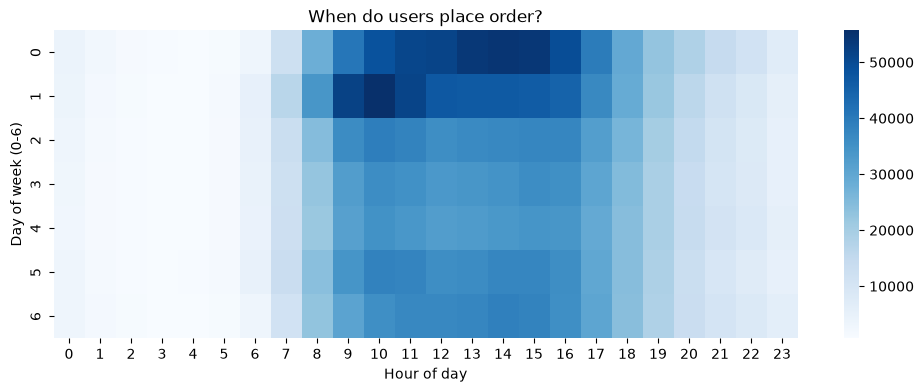

In [109]:
order_time = con.execute("""
    SELECT order_dow, order_hour_of_day, COUNT(*) AS n_orders
    FROM orders
    GROUP BY order_dow, order_hour_of_day
""").df()

grid = order_time.pivot(index = "order_dow", columns="order_hour_of_day", values="n_orders")

plt.figure(figsize=(12,4))
sns.heatmap(grid, cmap="Blues")
plt.xlabel("Hour of day")
plt.ylabel("Day of week (0-6)")
plt.title("When do users place order?")
plt.show()